In [1]:
from pathlib import Path
import subprocess
import os
import shutil

In [2]:
cudnn_dir = (
    "/home/ilove/profile/miniconda3/envs/FVDB/lib/"
    "python3.13/site-packages/nvidia/cudnn/lib"
)

env = os.environ.copy()

env["LD_LIBRARY_PATH"] = (
    cudnn_dir + ":" + env.get("LD_LIBRARY_PATH", "")
)

In [3]:
IMAGE_ROOT = Path("/mnt/c/Users/ilove/OneDrive - University of Cincinnati/CompSci/Fall2026/SeniorDesignSem1/Group-SkillForge/work/data/InterCap/01/05/Seg_0").resolve()
OUTPUT_ROOT = Path("/mnt/c/Users/ilove/Comp_Sci_Stuff/projects/SeniorDesign/experiments/COLMAP/exp1").resolve()

In [4]:
cameras = []
directories = sorted(p for p in IMAGE_ROOT.iterdir() if p.is_dir())
for dir in directories:
    cameras.append(dir / "color")

frames = sorted(p.name for p in cameras[0].glob("*.jpg"))

In [45]:
def reconstruct(frame_name):
    workspace = OUTPUT_ROOT / Path(frame_name).stem
    image_dir = workspace / "images"

    for camera in cameras:
        source = camera / frame_name
        if not source.is_file():
            raise FileNotFoundError(source)

        dest = image_dir / camera.parent.name / frame_name
        dest.parent.mkdir(parents=True, exist_ok=True)

        if not dest.exists():
            os.link(source, dest)


    subprocess.run([
        "colmap", "automatic_reconstructor",
        "--workspace_path", str(workspace),
        "--image_path", str(image_dir),
        "--quality", "extreme",
        "--data_type", "individual",
        "--dense", "0",
        "--feature", "LOMA",
        "--single_camera", "0",
    ], 
    env=env,
    check=True)

In [46]:
reconstruct(frames[5])

I20261021 20:10:02.922667 43621 automatic_reconstruction.cc:276] === Feature extraction ===
I20261021 20:10:02.923313 43622 feature_extraction.cc:471] === Feature extraction ===
I20261021 20:10:37.595644 43640 feature_extraction.cc:243] Processed file [1/6]
I20261021 20:10:37.595846 43640 feature_extraction.cc:246]   Name:            Frames_Cam1/00005.jpg
I20261021 20:10:37.595855 43640 feature_extraction.cc:255]   Dimensions:      1920 x 1080
I20261021 20:10:37.595858 43640 feature_extraction.cc:258]   Camera:          #1 - SIMPLE_RADIAL
I20261021 20:10:37.595866 43640 feature_extraction.cc:262]   Focal Length:    2304.00px
I20261021 20:10:37.595882 43640 feature_extraction.cc:267]   Features:        2048 (LOMA_B)
I20261021 20:11:22.972512 43640 feature_extraction.cc:243] Processed file [2/6]
I20261021 20:11:22.972697 43640 feature_extraction.cc:246]   Name:            Frames_Cam2/00005.jpg
I20261021 20:11:22.972715 43640 feature_extraction.cc:255]   Dimensions:      1920 x 1080
I2026

In [14]:
import logging

import cv2
import fvdb
import matplotlib.pyplot as plt
import numpy as np
import torch

import fvdb_reality_capture as frc
from fvdb_reality_capture.radiance_fields.gaussian_splat_reconstruction import GaussianSplatReconstructionConfig, GaussianSplatOptimizerConfig

In [7]:
workspace = OUTPUT_ROOT / Path(frames[5]).stem
print(workspace)

# Initialize the fvdb.viz module for interactive 3D visualization.
# This will spin up a small HTTP server in the background.
fvdb.viz.init(port=8080)

/mnt/c/Users/ilove/Comp_Sci_Stuff/projects/SeniorDesign/experiments/COLMAP/exp1/00005
Viewer Info: Running in headless mode - no GLFW window created


100%|██████████| 1284/1284 [00:00<00:00, 359775.96it/s]


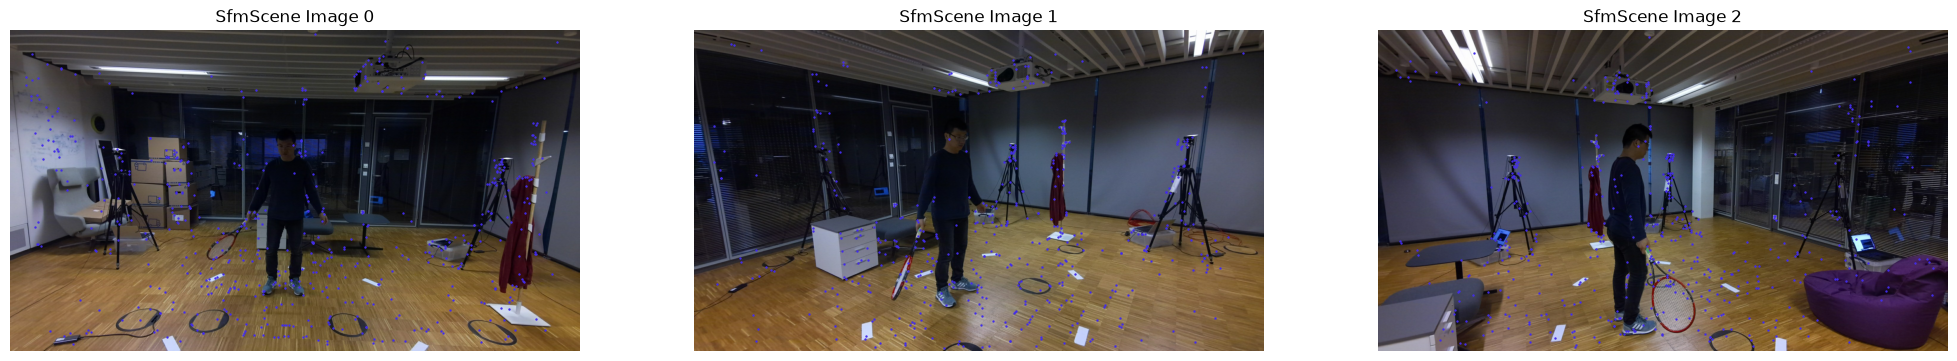

Viewer Info: Render loop stopped

Viewer Info: Running in headless mode - no GLFW window created
Viewer Info: Render loop started

Viewer Warning: Vulkan Video Encode is not supported, falling back to OpenH264
Viewer Info: Server created on port(8080)
Viewer Info: Running on server 127.0.0.1:8080


In [47]:
dataset_path = workspace
sfm_scene = frc.sfm_scene.SfmScene.from_colmap(dataset_path)

# Visualize an image in an SfmScene and the 3D points visible from that images
# projected onto the image plane as blue dots.
def plot_image_from_scene(scene: frc.sfm_scene.SfmScene, image_id: int):
    image_meta: frc.sfm_scene.SfmPosedImageMetadata = scene.images[image_id]
    camera_meta: frc.sfm_scene.SfmCameraMetadata = image_meta.camera_metadata

    # Get the visible 3d points for this image
    visible_points_3d: np.ndarray = scene.points[image_meta.point_indices]

    # Project those points onto the image plane
    # 1. Get the world -> camera space transform and projection matrix
    world_to_cam_matrix: np.ndarray = image_meta.world_to_camera_matrix
    projection_matrix: np.ndarray = camera_meta.projection_matrix
    # 2. Transform world points to camera space
    visible_points_3d_cam_space = world_to_cam_matrix[:3,:3] @ visible_points_3d.T + world_to_cam_matrix[:3,3:4]
    # 3. Transform camera space coordinates to image space
    visible_points_2d = projection_matrix @ visible_points_3d_cam_space
    visible_points_2d /= visible_points_2d[2]

    # Load the image and convert to RGB (OpenCV uses BGR by default)
    loaded_image = cv2.imread(image_meta.image_path)
    assert loaded_image is not None, f"Failed to load image at {image_meta.image_path}"
    loaded_image = cv2.cvtColor(loaded_image, cv2.COLOR_BGR2RGB)

    # Plot the image and projected points
    plt.title(f"SfmScene Image {image_id}")
    plt.axis("off")
    plt.imshow(loaded_image)
    plt.scatter(visible_points_2d[0], visible_points_2d[1], color="#432de9", marker=".", s=2)

# Visualize the SfmScene interactively in a 3D viewer using fvdb.viz.Viewer
def visualize_sfm_scene(scene: frc.sfm_scene.SfmScene,
                        name: str,
                        center_scene: bool = False):

    viewer_scene = fvdb.viz.get_scene("SfmScene Visualization")
    viewer_scene.reset()
    # Optionally center the scene at the origin.
    # This is useful to visualize multiple scenes together without them being far apart.
    if center_scene:
        center_transform = np.eye(4)
        center_transform[:3, 3] = -np.median(scene.points, axis=0)
        scene = scene.apply_transformation_matrix(center_transform)

    # Plot the points in the SfmScene with their colors (which are uint8 by default but the viewer
    # expects float32 colors in [0,1]).
    # Each point is drawn as a small sphere with a 2 pixel radius.
    viewer_scene.add_point_cloud(
        name=f"{name} Points",
        points=scene.points,
        colors=scene.points_rgb.astype(np.float32) / 255.0,
        point_size=2.0)

    # Plot the cameras as coordinate frames with axis length 2 units,
    # and frustums whose distance from the origin to camera plane is 1 unit long.
    viewer_scene.add_cameras(
        f"{name} Cameras",
        camera_to_world_matrices=scene.camera_to_world_matrices,
        projection_matrices=scene.projection_matrices,
        axis_length=2,
        frustum_scale=2.5,
    )

    # Set the initial camera view to be at the position of the first posed image, in the SfmScene,
    # looking at the center of the 3D points, with Z as up (COLMAP SfM scenes use Z as up).
    viewer_scene.set_camera_lookat(
        eye=scene.image_camera_positions[0],
        center=np.zeros(3),
        up=np.array([0, 0, 1]),  # Z is up in COLMAP SfM scenes
    )


# Plot three images from the scene and their visible 3D points alongside each other
plt.figure(figsize=(25, 4.25))
plt.subplot(1, 3, 1)
plot_image_from_scene(sfm_scene, 0)
plt.subplot(1, 3, 2)
plot_image_from_scene(sfm_scene, 1)
plt.subplot(1, 3, 3)
plot_image_from_scene(sfm_scene, 2)
plt.show()

# View the SfmScene interactively in a 3D viewer
visualize_sfm_scene(sfm_scene, "Raw SfmScene", center_scene=True)
fvdb.viz.show()

In [48]:
import fvdb_reality_capture.transforms as fvtransforms

# Clean up and resize the SfmScene using a transform pipeline which downsamples images,
# aligns the scene with its principle axes and centers it at (0, 0, 0),
# filters outlier points, and removes images with too few points.
cleanup_and_resize_transform = fvtransforms.Compose(
    # fvtransforms.DownsampleImages(image_downsample_factor=4, image_type="jpg", rescaled_jpeg_quality=95),
    fvtransforms.NormalizeScene(normalization_type="pca"),
    # fvtransforms.PercentileFilterPoints(percentile_min=3.0, percentile_max=97.0),
    # fvtransforms.FilterImagesWithLowPoints(min_num_points=50),
)
cleaned_sfm_scene = cleanup_and_resize_transform(sfm_scene)

print(f"Original scene had {len(sfm_scene.points)} points and {len(sfm_scene.images)} images")
print(f"Cleaned scene has {len(cleaned_sfm_scene.points)} points and {len(cleaned_sfm_scene.images)} images")

# Visualize the transformed scene so we can see the effect of the cleanup and resizing
# Note that we don't have to center the scene here since the normalization transform already did that.
# visualize_sfm_scene(cleaned_sfm_scene, "Cleaned SfmScene", center_scene=False)

Original scene had 1284 points and 6 images
Cleaned scene has 1284 points and 6 images


In [52]:
# We'll just reconstruct our scene using the default settings, which are good in most cases.
# See the documentation for `frc.GaussianSplatReconstruction` for details on the available options.
# Note that this process can take a while depending on the size of your scene.

config = GaussianSplatReconstructionConfig(sparse_depth_reg=0.2,
                                           max_epochs=200 # Default 200
                                           )
optimizer_config = GaussianSplatOptimizerConfig(deletion_opacity_threshold=0.05, # Defaut 0.005
                                                #insertion_grad_2d_threshold=0.000002,
                                                # deletion_scale_3d_threshold=0.1,  # Default 0.1
                                                # deletion_scale_2d_threshold=0.15,  #Default 0.15
                                                # insertion_scale_3d_threshold=1,
                                                insertion_scale_2d_threshold=0.01, # Default 0.05
                                                insertion_duplication_factor=3, # Default 2
                                                insertion_split_factor=3, # Default 2
                                                )

runner = frc.radiance_fields.GaussianSplatReconstruction.from_sfm_scene(cleaned_sfm_scene, 
                                                                        config=config, 
                                                                        optimizer_config=optimizer_config)
runner.optimize()

Gaussian Splat Reconstruction:   0%|          | 0/1200 [00:00<?, ?steps/s]
loss=0.165| sh degree=3| num gaussians=923: 100%|██████████| 1200/1200 [00:45<00:00, 26.50steps/s]


In [53]:
# Get the trained splat model from the reconstruction runner
model: frc.GaussianSplat3d = runner.model
# model, metadata = frc.GaussianSplat3d.from_ply("./reconstructed_model.ply")

# Clear previous contents from the viewer
# viewer.clear()

# Add our splat model to the viewer
scene = fvdb.viz.get_scene("Gaussian Splat Model Visualization")
view_data = frc.gaussian_splat_to_view_data(model)
scene.add_gaussian_splat_3d("Reconstructed Gaussian Splat Radiance Field", view_data)

scene.add_cameras(
    "Input Cameras",
    camera_to_world_matrices=cleaned_sfm_scene.camera_to_world_matrices,
    projection_matrices=cleaned_sfm_scene.projection_matrices,
    axis_length=2,
    frustum_scale=2.5,
)

# Set up the viewer's initial camera to be positioned at the first camera in the SfmScene
# looking at the center of the scene. This should give a good initial view of the model.
camera_position = cleaned_sfm_scene.images[0].origin
camera_lookat_point = model.means.mean(dim=0)
scene.set_camera_lookat(eye=camera_position, center=camera_lookat_point, up=(0, 0, 1)) # Colmap uses Z as up
fvdb.viz.show()

Reconstructed Gaussian Splat Model has 923, is on device cuda:0, and renders images with 3 channels.


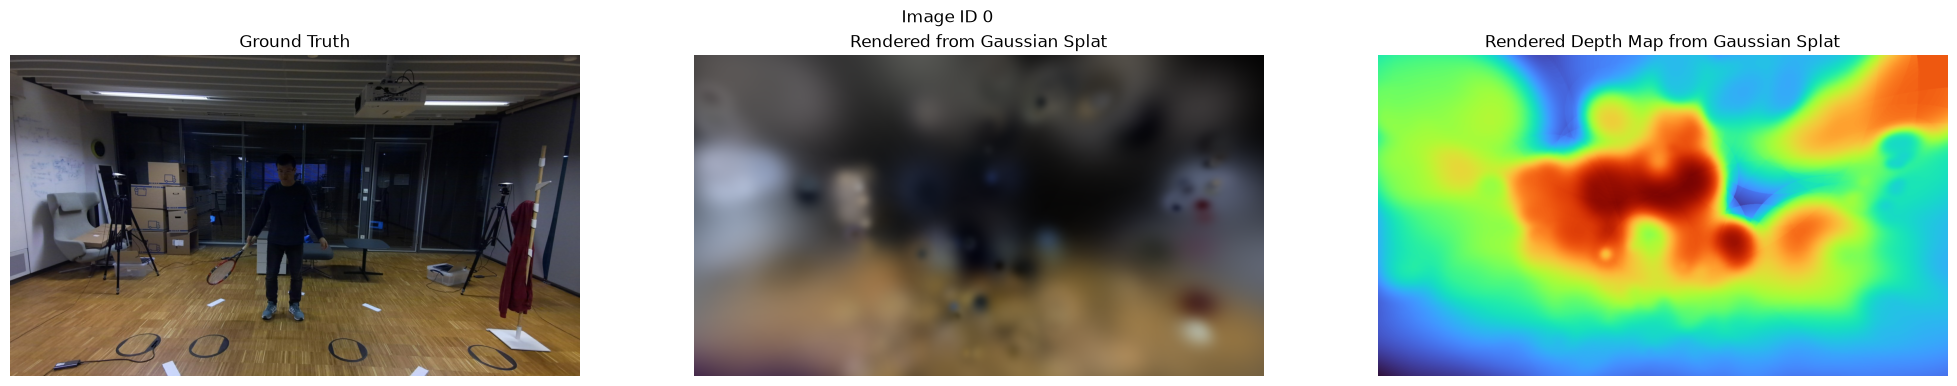

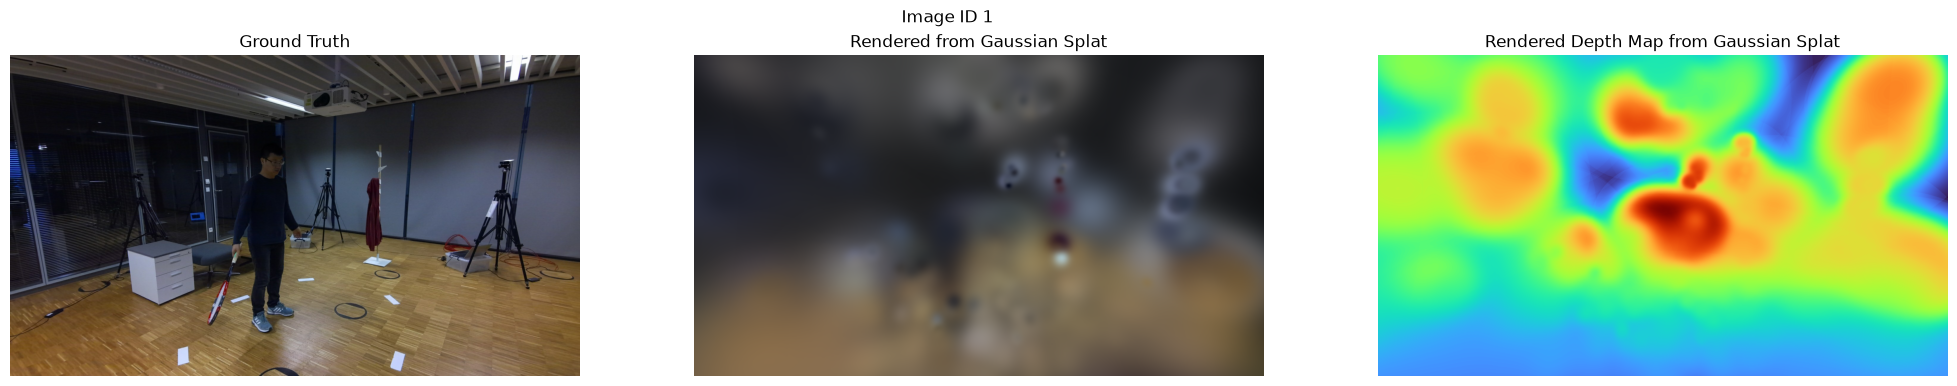

In [54]:
@torch.no_grad()
def plot_reconstruction_results(model: frc.GaussianSplat3d, sfm_scene: frc.sfm_scene.SfmScene, image_id: int):
    # Get one of the images and its camera from the scene
    image_meta: frc.sfm_scene.SfmPosedImageMetadata = sfm_scene.images[image_id]
    camera_meta: frc.sfm_scene.SfmCameraMetadata = image_meta.camera_metadata
    camera_to_world_matrix = torch.from_numpy(image_meta.camera_to_world_matrix).to(device=model.device, dtype=torch.float32)
    projection_matrix = torch.from_numpy(camera_meta.projection_matrix).to(device=model.device, dtype=torch.float32)
    image_height, image_width = image_meta.image_size

    # Read the ground truth image from disk
    gt_image = cv2.imread(image_meta.image_path)
    assert gt_image is not None, f"Failed to load image at {image_meta.image_path}"
    gt_image = cv2.cvtColor(gt_image, cv2.COLOR_BGR2RGB)

    # Render the image and a depth map from the Gaussian splat model
    rendered_rgbd, alphas = model.render_images_and_depths(
        world_to_camera_matrices=camera_to_world_matrix.inverse().unsqueeze(0).contiguous(),
        projection_matrices=projection_matrix.unsqueeze(0),
        image_width=image_width,
        image_height=image_height,
        near=0.1,
        far=10000.0,
    )
    rgb = rendered_rgbd[0, ..., :3].cpu().numpy()
    depth = (rendered_rgbd[0, ..., 3] / alphas.squeeze()).cpu().numpy()
    rendered_image = np.clip(rgb, 0.0, 1.0)
    rendered_image = (rendered_image * 255).astype(np.uint8)

    # Plot the ground truth and rendered images side by side
    plt.figure(figsize=(25, 4.25))
    plt.suptitle(f"Image ID {image_id}")
    plt.subplot(1, 3, 1)
    plt.title("Ground Truth")
    plt.axis("off")
    plt.imshow(gt_image)
    plt.subplot(1, 3, 2)
    plt.title("Rendered from Gaussian Splat")
    plt.axis("off")
    plt.imshow(rendered_image)
    plt.subplot(1, 3, 3)
    plt.title("Rendered Depth Map from Gaussian Splat")
    plt.axis("off")
    plt.imshow(depth, cmap="turbo")
    plt.show()

model: frc.GaussianSplat3d = runner.model
print(f"Reconstructed Gaussian Splat Model has {model.num_gaussians}, is on device {model.device}, and renders images with {model.num_channels} channels.")
plot_reconstruction_results(model, cleaned_sfm_scene, image_id=0)
plot_reconstruction_results(model, cleaned_sfm_scene, image_id=1)
